# Delivery vs Customer Satisfaction

Does delivery performance affect customer satisfaction?

Investigate the relationship between:

1. Delivery delay and review score 
2. Total delivery time and review score 


### 0. Get data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.cloud import bigquery
from pathlib import Path

In [2]:
IMG_PATH = Path("../images")
IMG_PATH.mkdir(exist_ok=True)

In [3]:
DATA_PATH = Path("../data/fact_orders.parquet")
PROJECT_ID = "olist-inigoochoa"
client = bigquery.Client(project=PROJECT_ID)

if DATA_PATH.exists():
    df = pd.read_parquet(DATA_PATH)
else:
    df = client.query(f"""
        SELECT
            order_status,
            order_purchase_timestamp,
            order_estimated_delivery_date,
            order_delivered_customer_date,
            delivery_delay_days,
            total_delivery_days,
            is_late_delivery,
            avg_review_score
        FROM `{PROJECT_ID}.olist_analytics.fact_orders`
    """).to_dataframe()
    DATA_PATH.parent.mkdir(exist_ok=True)
    df.to_parquet(DATA_PATH)

C:\Users\inigo\AppData\Local\Programs\Python\Python314\Lib\site-packages\google\auth\_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


## 1. Delivery delay and review score
Only orders that have been delivered, have a valid delivered date and have a review score are analysed.

In [4]:
deliv_delay = df.copy()
orders_0 = deliv_delay.shape[0]
print(f"Total orders: {orders_0}")

Total orders: 99441


In [5]:
deliv_delay = deliv_delay[(deliv_delay.order_status == "delivered") & (deliv_delay.order_delivered_customer_date.notna())]
orders_1 = deliv_delay.shape[0]
print(f"Remaining orders: {orders_1}")
print(f"Filtered orders in this step: {orders_0 - orders_1}")

Remaining orders: 96470
Filtered orders in this step: 2971


In [6]:

df_reviewed = deliv_delay[deliv_delay.avg_review_score.notna()].copy()
deliv_delay = df_reviewed.copy()
orders_2 = deliv_delay.shape[0]
print(f"Remaining orders: {orders_2}")
print(f"Filtered orders in this step: {orders_1 - orders_2}")
print(f"Percentage of orders remaining: {orders_2 * 100/ orders_0:.2f}%")

Remaining orders: 95824
Filtered orders in this step: 646
Percentage of orders remaining: 96.36%


Orders are grouped by delivery delay in days:
- 15+ days early
- 8-14 days early
- 1-7 days early
- On time
- 1-3 days late
- 4-7 days late
- 8+ days late

In [7]:
deliv_delay["delay_bucket"] = pd.cut(deliv_delay.delivery_delay_days, bins=[-np.inf, -15, -8, -1, 0, 3, 7, np.inf], labels=["15+ days early", "8-14 days early", "1-7 days early", "On time", "1-3 days late", "4-7 days late", "8+ days late"])


In [8]:
deliv_delay.delay_bucket.value_counts(sort=False, dropna=False)

delay_bucket
15+ days early     34771
8-14 days early    36158
1-7 days early     17234
On time             1280
1-3 days late       1852
4-7 days late       1748
8+ days late        2781
Name: count, dtype: int64

In [9]:
delay_prop = (deliv_delay.delay_bucket.value_counts(sort=False, dropna=False, normalize=True)*100).reset_index()
delay_prop["cumulative_pct"] = delay_prop.proportion.cumsum()
delay_prop

,delay_bucket,proportion,cumulative_pct
0,15+ days early,36.286317,36.286317
1,8-14 days early,37.733762,74.020078
2,1-7 days early,17.985056,92.005134
3,On time,1.335782,93.340917
4,1-3 days late,1.932710,95.273627
5,4-7 days late,1.824178,97.097804
6,8+ days late,2.902196,100.000000


- 93% of orders are delivered on or before the estimated date, and 74% arrive at least 8 days early.
- Only 6.7% of orders are late
  
Olist's delivery estimates are highly conservative.

In [10]:
deldays = deliv_delay.groupby("delay_bucket", observed=False).agg(
    avg_review_score = ("avg_review_score", "mean"),
    n_orders = ("avg_review_score", "count")).reset_index()

In [11]:
deldays

,delay_bucket,avg_review_score,n_orders
0,15+ days early,4.323013,34771
1,8-14 days early,4.311208,36158
2,1-7 days early,4.200853,17234
3,On time,4.035547,1280
4,1-3 days late,3.291037,1852
5,4-7 days late,2.105549,1748
6,8+ days late,1.697591,2781


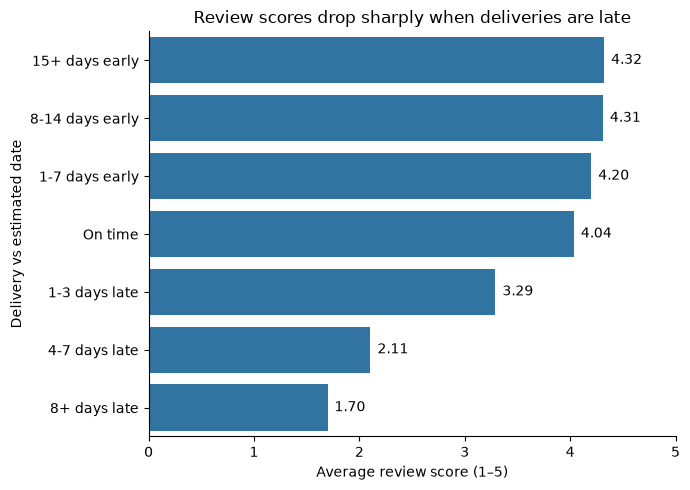

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=deldays, x="avg_review_score", y="delay_bucket", ax=ax)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=5)
ax.set_xlim(0, 5)

ax.set_xlabel("Average review score (1–5)")
ax.set_ylabel("Delivery vs estimated date")
ax.set_title("Review scores drop sharply when deliveries are late")

sns.despine()
plt.tight_layout()

fig.savefig(IMG_PATH / "07a_review_by_delay_bucket.png",
            dpi=150, bbox_inches="tight", facecolor="white")


### The impact of delivery timing on reviews is asymmetric

Arriving early adds little: orders delivered 15+ days early score 4.32 on average, only 0.3 points above on-time deliveries (4.04). Arriving late is heavily penalised: the score drops to 3.29 at 1–3 days late and to 1.70 beyond 7 days.

Since 93% of orders arrive on or before the estimated date, Olist’s conservative estimates are consistent with protecting satisfaction: tightening them would move more orders into the zone where reviews collapse.

## 2. Total delivery time and review score


In [13]:
del_time_vs_review_score = df_reviewed.copy()

In [14]:
del_time_vs_review_score["purchase_to_delivery_bucket"] = pd.cut(del_time_vs_review_score.total_delivery_days, bins=[-1, 2, 7, 14, 21, 30, np.inf], labels=["0-2 days", "3-7 days", "8-14 days", "15-21 days", "22-30 days", "31+ days"])


In [15]:
del_time_vs_review_score.purchase_to_delivery_bucket.value_counts(sort=False)

purchase_to_delivery_bucket
0-2 days       3492
3-7 days      27058
8-14 days     37775
15-21 days    16054
22-30 days     7265
31+ days       4180
Name: count, dtype: int64

In [16]:
late_orders = del_time_vs_review_score[del_time_vs_review_score.is_late_delivery]
late_orders_grouped = late_orders.groupby("purchase_to_delivery_bucket", observed=False).agg(
    avg_review_score = ("avg_review_score", "mean"),
    n_orders = ("avg_review_score", "count"))

late_orders_grouped["pct_of_total_orders"] = late_orders_grouped.n_orders * 100 / late_orders_grouped.n_orders.sum()
late_orders_grouped["cumulative_pct_of_orders"] = round(late_orders_grouped.pct_of_total_orders.cumsum(), 2)
late_orders_grouped

,avg_review_score,n_orders,pct_of_total_orders,cumulative_pct_of_orders
purchase_to_delivery_bucket,,,,
0-2 days,NaN,0,0.000000,0.00
3-7 days,3.972973,74,1.159693,1.16
8-14 days,3.269461,334,5.234289,6.39
15-21 days,2.939759,581,9.105156,15.50
22-30 days,2.547119,2048,32.095283,47.59
31+ days,1.849880,3344,52.405579,100.00


In [17]:
on_time_orders = del_time_vs_review_score[~del_time_vs_review_score.is_late_delivery]


In [18]:
on_time_orders_grouped = on_time_orders.groupby("purchase_to_delivery_bucket", observed=False).agg(
    avg_review_score = ("avg_review_score", "mean"),
    n_orders = ("avg_review_score", "count"))

on_time_orders_grouped["pct_of_total_orders"] = on_time_orders_grouped.n_orders * 100 / on_time_orders_grouped.n_orders.sum()
on_time_orders_grouped["cumulative_pct_of_orders"] = round(on_time_orders_grouped.pct_of_total_orders.cumsum(), 2)
on_time_orders_grouped

,avg_review_score,n_orders,pct_of_total_orders,cumulative_pct_of_orders
purchase_to_delivery_bucket,,,,
0-2 days,4.494273,3492,3.904162,3.90
3-7 days,4.402992,26984,30.168934,34.07
8-14 days,4.308111,37441,41.860179,75.93
15-21 days,4.161604,15473,17.299286,93.23
22-30 days,3.937001,5217,5.832765,99.07
31+ days,3.620813,836,0.934673,100.00


In [19]:
late_vs_on_time_grouped = on_time_orders_grouped.reset_index().merge(late_orders_grouped.reset_index(), how="left", on="purchase_to_delivery_bucket", suffixes=["_on_time", "_late"])#

In [20]:
late_vs_on_time_grouped = late_vs_on_time_grouped[["purchase_to_delivery_bucket", "avg_review_score_on_time", "avg_review_score_late", "n_orders_on_time", "n_orders_late"]]

In [21]:
late_vs_on_time_grouped["late_penalty"] = late_vs_on_time_grouped.avg_review_score_on_time - late_vs_on_time_grouped.avg_review_score_late

In [22]:
late_vs_on_time_grouped.round(2).set_index("purchase_to_delivery_bucket")

,avg_review_score_on_time,avg_review_score_late,n_orders_on_time,n_orders_late,late_penalty
purchase_to_delivery_bucket,,,,,
0-2 days,4.49,NaN,3492,0,NaN
3-7 days,4.40,3.97,26984,74,0.43
8-14 days,4.31,3.27,37441,334,1.04
15-21 days,4.16,2.94,15473,581,1.22
22-30 days,3.94,2.55,5217,2048,1.39
31+ days,3.62,1.85,836,3344,1.77


### Delivery time matters, but being late matters much more

1. Long deliveries are penalised even when they arrive on time.
Among on-time orders, the average review falls from 4.49 (0–2 days) to 3.62 (31+ days), a 0.87-point drop. Customers dislike long waits even when the delivery promise is kept.

2. Being late adds a much larger penalty on top.
For the same total delivery time, late orders score 1.0–1.8 points below on-time orders (1.04 at 8–14 days, 1.77 at 31+ days). The 3–7 day bucket (0.43) is based on only 74 late orders and is not reliable.

3. The collapse in long deliveries is largely a mix effect.
The overall average for 31+ day orders (2.20) looks dramatic because 80% of those orders are late, compared with under 1% in the 8–14 day bucket. Total delivery time alone does not explain the drop.

Keeping the delivery promise matters more than delivery speed. This is consistent with point 1: Olist's conservative estimates protect satisfaction by keeping most orders on the right side of the promise.

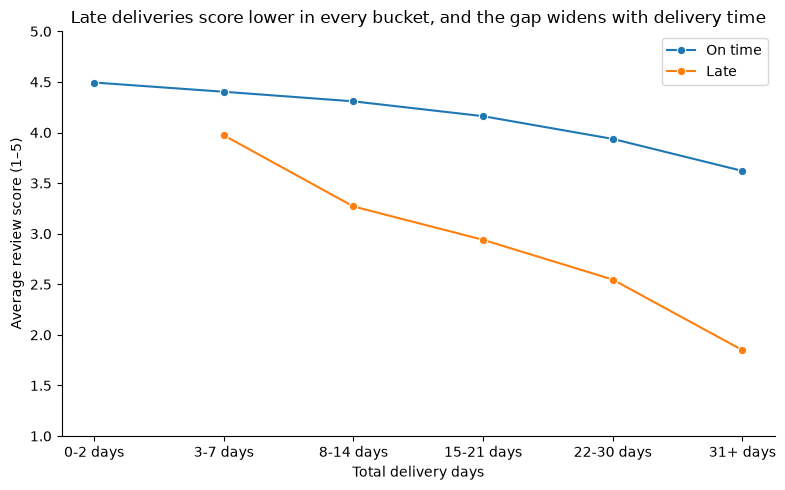

In [ ]:
plot_df = (
    late_vs_on_time_grouped
    .reset_index()
    .rename(columns={
        "avg_review_score_on_time": "On time",
        "avg_review_score_late": "Late",
    })
    .melt(
        id_vars="purchase_to_delivery_bucket",
        value_vars=["On time", "Late"],
        var_name="delivery_status",
        value_name="avg_review_score",
    )
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(
    data=plot_df,
    x="purchase_to_delivery_bucket",
    y="avg_review_score",
    hue="delivery_status",
    marker="o",
    ax=ax,
)

ax.set_ylim(1, 5)
ax.set_xlabel("Total delivery days")
ax.set_ylabel("Average review score (1–5)")
ax.set_title("Late deliveries score lower in every bucket, and the gap widens with delivery time")
ax.legend(title=None)

sns.despine()
plt.tight_layout()

fig.savefig(IMG_PATH / "07b_late_vs_on_time_by_delivery_time.png",
            dpi=150, bbox_inches="tight", facecolor="white")